# EDA (домен reviews)

Reviews — отзывы пользователей о брендах: оценка от 1 до 5, иногда текст и его эмбеддинг. Отзыв оставляют на бренд (партнёра, заведение, сервис), а не на конкретный товар.

Основные файлы в `dataset/small/`:

| Файл | Что хранится |
|---|---|
| `reviews/{day}.pq` | Отзывы за один день: время, пользователь, бренд, оценка, текст и эмбеддинг текста |
| `users.pq` | Общая таблица пользователей: ID, регион и соцдем-кластер |
| `brands.pq` | Общая таблица брендов: ID и эмбеддинг |


In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

PATH = Path("../t_ecd_data/dataset/small")
plt.rcParams["figure.figsize"] = (12, 5)
pl.Config.set_fmt_str_lengths(80)


polars.config.Config

## 1. Загрузка данных

Отзывы лежат по одному файлу на день, читаем все файлы лениво через `scan_parquet`. 
Все справочники читаем сразу, так как они небольшие.


In [2]:
reviews = pl.scan_parquet(PATH / "reviews/*.pq")
users = pl.read_parquet(PATH / "users.pq")
brands = pl.read_parquet(PATH / "brands.pq")

for name, df in [("reviews", reviews), ("users", users), ("brands", brands)]:
    schema = df.collect_schema() if isinstance(df, pl.LazyFrame) else df.schema
    print(f"{name}: {dict(schema)}\n")


reviews: {'timestamp': Duration(time_unit='us'), 'user_id': UInt64, 'brand_id': UInt64, 'rating': UInt8, 'text': String, 'embedding': Array(Float32, shape=(312,))}

users: {'user_id': UInt64, 'socdem_cluster': UInt8, 'region': UInt8}

brands: {'brand_id': UInt64, 'embedding': Array(Float32, shape=(300,))}



Первые отзывы без эмбеддинга и отдельно первые отзывы с текстом:

In [3]:
display(reviews.select(pl.exclude("embedding")).head(5).collect())
display(reviews.select(pl.exclude("embedding")).filter(pl.col("text").is_not_null()).head(5).collect())
display(users.head(3))
display(brands.head(3))


timestamp,user_id,brand_id,rating,text
duration[μs],u64,u64,u8,str
1082d 1m 5s 711723µs,25741061,141226,5,null
1082d 1m 12s 26501µs,71011848,65693,3,null
1082d 2m 15s 540704µs,26101012,72285,5,null
1082d 2m 25s 126055µs,67977146,184380,3,null
1082d 2m 36s 993924µs,4055428,216938,5,null


timestamp,user_id,brand_id,rating,text
duration[μs],u64,u64,u8,str
1082d 5m 31s 327352µs,6227233,165140,5,"""The service was prompt and of high quality!"""
1082d 8m 2s 375164µs,15985966,117492,5,"""I had a tasty, satisfying meal with live music, making for a trendy and enjoyabl…"
1082d 10m 18s 984571µs,10612172,78944,5,"""I really enjoy this service, which allows me to avoid queues at the ticket count…"
1082d 10m 32s 482345µs,63241372,75487,5,"""The establishment is consistently well-stocked, and we frequently purchase from …"
1082d 10m 56s 237762µs,63241372,68040,5,"""My favorite place has everything! Especially, the food at a nearby establishment…"


user_id,socdem_cluster,region
u64,u8,u8
77309558,21,2
72517894,10,90
86699708,9,9


brand_id,embedding
u64,"array[f32, 300]"
4,null
34,null
45,null


### 1.1. Базовые размеры

In [4]:
overview = reviews.select(
    pl.len().alias("n_reviews"),
    pl.col("user_id").n_unique().alias("n_users"),
    pl.col("brand_id").n_unique().alias("n_brands"),
    pl.col("timestamp").dt.total_days().min().alias("first_day"),
    pl.col("timestamp").dt.total_days().max().alias("last_day"),
    pl.col("timestamp").dt.total_days().n_unique().alias("n_days"),
).collect()
display(overview)

print(f"Пользователей с отзывами: {overview['n_users'][0] / users.height:.1%} от users.pq")
print(f"Брендов с отзывами: {overview['n_brands'][0] / brands['brand_id'].n_unique():.1%} от brands.pq")


n_reviews,n_users,n_brands,first_day,last_day,n_days
u32,u32,u32,i64,i64,u32
363970,103834,24467,1082,1308,227


Пользователей с отзывами: 3.0% от users.pq
Брендов с отзывами: 83.1% от brands.pq


### 1.2. Что хранится в `timestamp`

`timestamp` — это не дата, а длительность `Duration`: номер дня от некоторой точки отсчёта плюс время внутри дня. Проверяем, что номер дня совпадает с именем файла:

In [5]:
day_check = (
    pl.scan_parquet(PATH / "reviews/*.pq", include_file_paths="file")
    .select(
        pl.col("file").str.extract(r"(\d+)\.pq$").cast(pl.Int64).alias("file_day"),
        pl.col("timestamp").dt.total_days().alias("ts_day"),
    )
    .filter(pl.col("file_day") != pl.col("ts_day"))
    .collect()
)
print("Отзывов, у которых день в timestamp не совпадает с именем файла:", day_check.height)


Отзывов, у которых день в timestamp не совпадает с именем файла: 0


**Выводы**
- 363 970 отзывов за 227 дней подряд (дни 1082–1308)
- Отзывы оставили 103 834 пользователя, это всего 3% от `users.pq`. Отзывы пишет небольшая часть клиентов
- Отзывы есть у 24 467 брендов, это 83% справочника `brands.pq`. Значит, reviews может дать признак почти для каждого бренда
- `timestamp` хранит номер дня и время внутри дня. День во всех записях совпадает с именем файла
- У отзыва нет `item_id`: оценка ставится бренду. Связывать reviews с другими доменами можно только через `user_id` и `brand_id`
- Тексты на английском. Во многих строках `text` = null, в следующем пункте об этом подробнее
- Эмбеддинг отзыва имеет размерность 312, а эмбеддинг бренда 300. Это разные модели, напрямую их сравнивать нельзя


## 2. Пропуски

### 2.1. Пропуски в отзывах


In [6]:
n = reviews.select(pl.len()).collect().item()
nulls = reviews.select(pl.all().is_null().sum()).collect()
display(
    nulls.transpose(include_header=True, header_name="column", column_names=["n_null"])
    .with_columns((pl.col("n_null") / n).round(4).alias("share"))
)


column,n_null,share
str,u32,f64
"""timestamp""",0,0.0
"""user_id""",0,0.0
"""brand_id""",0,0.0
"""rating""",0,0.0
"""text""",300001,0.8242
"""embedding""",299020,0.8216


Пропуски есть только в `text` и `embedding`. Проверим, совпадают ли они. Дальше эмбеддинг целиком не нужен, поэтому заменяем его хешем, по нему удобно искать одинаковые векторы.


In [7]:
reviews_flags = reviews.select(
    pl.exclude("embedding"),
    pl.col("text").is_not_null().alias("has_text"),
    pl.col("embedding").is_not_null().alias("has_emb"),
    pl.col("embedding").hash().alias("emb_hash"),
).collect()

display(reviews_flags.group_by("has_text", "has_emb").len().sort("has_text", "has_emb"))


has_text,has_emb,len
bool,bool,u32
false,false,299020
false,true,981
true,true,63969


Текст без эмбеддинга не встречается, а эмбеддинг без текста бывает. Посмотрим на такие отзывы:


In [8]:
emb_only = reviews_flags.filter(~pl.col("has_text") & pl.col("has_emb"))
text_hashes = reviews_flags.filter(pl.col("has_text")).select("emb_hash").unique()

print("Отзывов с эмбеддингом, но без текста:", emb_only.height)
print("Уникальных эмбеддингов среди них:", emb_only["emb_hash"].n_unique())
print("Из них совпадают с эмбеддингом какого-то текста:", emb_only.join(text_hashes, on="emb_hash", how="semi").height)
display(emb_only.group_by("emb_hash").len().sort("len", descending=True).head(3))


Отзывов с эмбеддингом, но без текста: 981
Уникальных эмбеддингов среди них: 666
Из них совпадают с эмбеддингом какого-то текста: 0


emb_hash,len
u64,u32
4036371118597620309,57
11701487755536445647,23
3739661982593360165,22


### 2.2. Случайны ли пропуски текста

Если текст пропущен случайно, его доля должна быть одинаковой при любой оценке:


In [9]:
display(
    reviews_flags.group_by("rating")
    .agg(pl.len().alias("n_reviews"), pl.col("has_text").mean().round(3).alias("share_with_text"))
    .sort("rating")
)


rating,n_reviews,share_with_text
u8,u32,f64
1,9955,0.297
2,4628,0.303
3,15089,0.277
4,36306,0.211
5,297992,0.16


Скрытые пропуски: тексты-заглушки, которые повторяются много раз.


In [10]:
display(
    reviews_flags.filter(pl.col("has_text"))
    .group_by("text").len()
    .sort("len", descending=True)
    .head(10)
)


text,len
str,u32
"""Neutral review.""",155
"""The service was excellent.""",56
"""There is a wide range of products available.""",53
"""I had a great experience at a store that provided excellent service.""",33
"""The products are always fresh.""",32
"""I enjoyed the service.""",25
"""A wide range of products is available.""",19
"""There is a wide variety of products available.""",18
"""Affordable and extensive range of products.""",18


### 2.3. Связь со справочниками

Проверяем, что все пользователи и бренды из отзывов есть в справочниках, и смотрим пропуски у них. В `brands.pq` у части брендов несколько строк (это разобрано в EDA offers, п. 1.2), поэтому эмбеддинг бренда считаем присутствующим, если он есть хотя бы в одной строке.


In [11]:
review_users = reviews_flags.select("user_id").unique()
review_brands = reviews_flags.select("brand_id").unique()

print("Пользователей из отзывов без записи в users.pq:", review_users.join(users, on="user_id", how="anti").height)
print("Брендов из отзывов без записи в brands.pq:", review_brands.join(brands, on="brand_id", how="anti").height)

brand_has_emb = brands.group_by("brand_id").agg(pl.col("embedding").is_not_null().any().alias("has_brand_emb"))
share_brand_emb = review_brands.join(brand_has_emb, on="brand_id")["has_brand_emb"].mean()
print(f"Брендов из отзывов с эмбеддингом в brands.pq: {share_brand_emb:.1%}")

reviewers = users.join(review_users, on="user_id", how="semi")
print(f"Пропуски у авторов отзывов: region {reviewers['region'].null_count() / reviewers.height:.3%}, "
      f"socdem_cluster {reviewers['socdem_cluster'].null_count() / reviewers.height:.3%}")


Пользователей из отзывов без записи в users.pq: 0
Брендов из отзывов без записи в brands.pq: 0
Брендов из отзывов с эмбеддингом в brands.pq: 26.7%
Пропуски у авторов отзывов: region 0.030%, socdem_cluster 0.002%


**Выводы**
- `timestamp`, `user_id`, `brand_id` и `rating` заполнены полностью
- Текста нет у 82% отзывов (300 001 из 363 970). В основном отзыв — это только оценка
- Пропуск текста не случайный: к оценкам 1–3 текст пишут почти в 30% случаев, к пятёркам только в 16%. Недовольные пользователи чаще объясняют оценку. Поэтому `has_text` сам по себе несёт сигнал
- Эмбеддинг всегда есть, если есть текст. Ещё у 981 отзыва эмбеддинг есть, а текста нет. Таких векторов всего 666 уникальных, один повторяется 57 раз, и ни один не совпадает с эмбеддингом существующего текста. **Гипотеза:** текст удалили уже после подсчёта эмбеддинга (например, при анонимизации). Для модели такие эмбеддинги можно использовать как есть
- Есть шаблонные тексты: "Neutral review." встречается 155 раз, а короткие фразы вроде "The service was excellent." десятки раз. Их мало, но на таких текстах эмбеддинг почти ничего не говорит
- Все пользователи и бренды из отзывов есть в справочниках. У авторов отзывов `region` и `socdem_cluster` почти всегда заполнены
- Эмбеддинг в `brands.pq` есть только у 27% брендов из отзывов. **Отзывы могут дать описание бренда там, где своего эмбеддинга у него нет:** например, средний эмбеддинг текстов или средняя оценка


## 3. Дубликаты и повторные отзывы

### 3.1. Полные дубли


In [12]:
print("Полных дублей отзывов:", reviews_flags.height - reviews_flags.unique().height)
print("Повторяющихся brand_id в brands.pq:", brands.height - brands["brand_id"].n_unique())


Полных дублей отзывов: 0
Повторяющихся brand_id в brands.pq: 32


### 3.2. Повторные отзывы одного пользователя на один бренд

Полных дублей нет, но один пользователь может оставить на бренд несколько отзывов. Посмотрим, сколько таких пар, через какое время приходит повторный отзыв и меняется ли оценка.


In [13]:
pairs = reviews_flags.group_by("user_id", "brand_id").agg(pl.len().alias("n"))
repeat = pairs.filter(pl.col("n") > 1)
print(f"Пар user × brand: {pairs.height:,}, из них с повторными отзывами: {repeat.height:,} ({repeat.height / pairs.height:.1%})")
print(f"Отзывов в таких парах: {repeat['n'].sum():,} ({repeat['n'].sum() / n:.1%}), максимум на пару: {repeat['n'].max()}")

gaps = (
    reviews_flags.sort("user_id", "brand_id", "timestamp")
    .with_columns(
        (pl.col("timestamp") - pl.col("timestamp").shift(1).over("user_id", "brand_id")).dt.total_seconds().alias("gap_sec"),
        (pl.col("rating") != pl.col("rating").shift(1).over("user_id", "brand_id")).alias("rating_changed"),
    )
    .filter(pl.col("gap_sec").is_not_null())
)

bins = [1, 60, 3600, 86400, 7 * 86400]
labels = ["<1с", "1с–1м", "1м–1ч", "1ч–1д", "1д–7д", ">7д"]
display(
    gaps.with_columns(pl.col("gap_sec").bin_intervals(bins, labels=labels).alias("gap"))
    .group_by("gap").len()
    .with_columns((pl.col("len") / pl.col("len").sum()).round(3).alias("share"))
    .sort("gap")
)
print(f"Доля повторов, где оценка изменилась: {gaps['rating_changed'].mean():.1%}")


Пар user × brand: 313,176, из них с повторными отзывами: 38,845 (12.4%)
Отзывов в таких парах: 89,639 (24.6%), максимум на пару: 71


gap,len,share
enum,u32,f64
"""<1с""",2,0.0
"""1с–1м""",125,0.002
"""1м–1ч""",6836,0.135
"""1ч–1д""",25752,0.507
"""1д–7д""",582,0.011
""">7д""",17497,0.344


Доля повторов, где оценка изменилась: 7.9%


Пара с наибольшим числом отзывов, по дням:


In [14]:
top_pair = repeat.sort("n", descending=True).row(0, named=True)
display(
    reviews_flags.filter((pl.col("user_id") == top_pair["user_id"]) & (pl.col("brand_id") == top_pair["brand_id"]))
    .group_by(pl.col("timestamp").dt.total_days().alias("day"))
    .agg(pl.len().alias("n_reviews"), pl.col("rating").mean().round(2).alias("mean_rating"))
    .sort("day")
    .head(10)
)


day,n_reviews,mean_rating
i64,u32,f64
1117,2,5.0
1133,7,4.86
1150,5,5.0
1155,4,4.75
1168,1,5.0
1169,1,5.0
1175,2,5.0
1180,2,5.0
1181,3,5.0


**Выводы**
- Полных дублей отзывов нет. В `brands.pq` 32 лишние строки с повторяющимися `brand_id`, они уже разобраны в EDA offers
- У 12.4% пар user x brand больше одного отзыва, и на них приходится четверть всех отзывов. Максимум — 71 отзыв одного пользователя на один бренд
- Это не двойная запись: меньше секунды между отзывами прошло всего в 2 случаях из 50 794, меньше минуты — в 0.25%
- Половина повторов приходит в тот же день (от часа до суток), ещё треть — больше чем через неделю. Промежуток 1–7 дней почти пустой (1%). **Гипотеза:** отзыв ставится на каждый визит или заказ. Пользователь возвращается к бренду регулярно (сети, кафе) и иногда оценивает несколько визитов за один день. У пары с максимумом отзывов как раз видно по 1–7 отзывов в разные дни
- Оценка меняется только в 8% повторов
- **Что делаем:** повторы не удаляем, это настоящие взаимодействия. Для модели "пользователь — бренд" их нужно агрегировать (число отзывов, средняя или последняя оценка), иначе частые посетители получат слишком большой вес


## 4. Распределения

**Настройки графиков**


In [15]:
from matplotlib.ticker import PercentFormatter

BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 1.6,
})


### 4.1. Оценки


rating,n,n_text,share
u8,u32,u32,f64
1,9955,2958,0.027351
2,4628,1401,0.012715
3,15089,4184,0.041457
4,36306,7655,0.09975
5,297992,47771,0.818727


mean,median
f64,f64
4.67,5.0


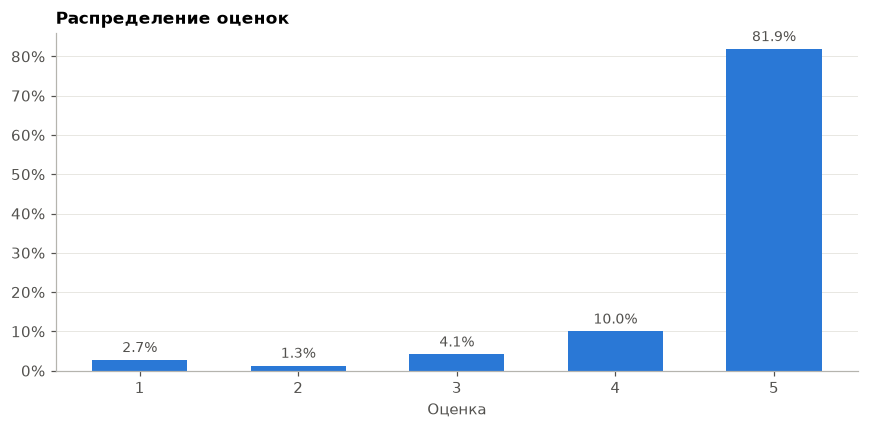

In [16]:
ratings = (
    reviews_flags.group_by("rating")
    .agg(pl.len().alias("n"), pl.col("has_text").sum().alias("n_text"))
    .sort("rating")
    .with_columns((pl.col("n") / pl.col("n").sum()).alias("share"))
)
display(ratings)
display(reviews_flags.select(pl.col("rating").mean().round(2).alias("mean"), pl.col("rating").median().alias("median")))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(ratings["rating"], ratings["share"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{s:.1%}" for s in ratings["share"]], padding=3, color=MUTED, fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Оценка")
ax.grid(axis="x", visible=False)
ax.set_title("Распределение оценок", loc="left")
fig.tight_layout()
plt.show()


### 4.2. Динамика по дням


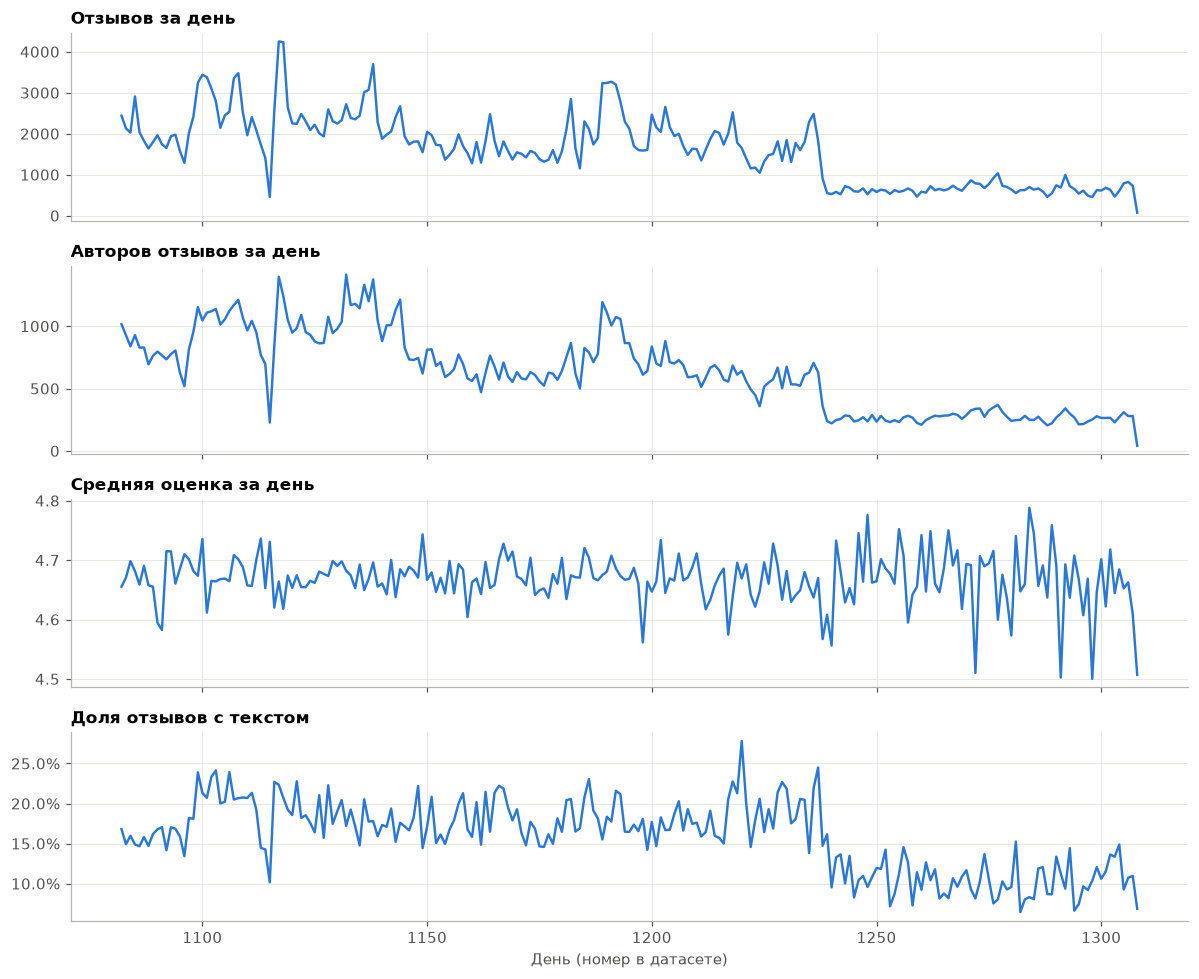

day,n_reviews,n_users,mean_rating,share_text
i64,u32,u32,f64,f64
1306,821,279,4.662607,0.107186
1307,730,280,4.609589,0.109589
1308,73,41,4.506849,0.068493


In [17]:
daily = (
    reviews_flags.group_by(pl.col("timestamp").dt.total_days().alias("day"))
    .agg(
        pl.len().alias("n_reviews"),
        pl.col("user_id").n_unique().alias("n_users"),
        pl.col("rating").mean().alias("mean_rating"),
        pl.col("has_text").mean().alias("share_text"),
    )
    .sort("day")
)

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
panels = [("n_reviews", "Отзывов за день"), ("n_users", "Авторов отзывов за день"),
          ("mean_rating", "Средняя оценка за день"), ("share_text", "Доля отзывов с текстом")]
for ax, (col, title) in zip(axes, panels):
    ax.plot(daily["day"], daily[col], color=BLUE)
    ax.set_title(title, loc="left")
axes[3].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[-1].set_xlabel("День (номер в датасете)")
fig.tight_layout()
plt.show()

display(daily.tail(3))


Около дня 1238 число отзывов резко падает. Сравним периоды до и после:


In [18]:
SHIFT_DAY = 1239

periods = reviews_flags.with_columns(
    pl.when(pl.col("timestamp").dt.total_days() < SHIFT_DAY).then(pl.lit("до 1239")).otherwise(pl.lit("с 1239")).alias("period")
)
display(
    periods.group_by("period")
    .agg(
        pl.col("timestamp").dt.total_days().n_unique().alias("n_days"),
        (pl.len() / pl.col("timestamp").dt.total_days().n_unique()).round(0).alias("reviews_per_day"),
        pl.col("user_id").n_unique().alias("n_users"),
        pl.col("rating").mean().round(3).alias("mean_rating"),
        pl.col("has_text").mean().round(3).alias("share_text"),
    )
    .sort("period")
)

users_before = periods.filter(pl.col("period") == "до 1239").select("user_id").unique()
users_after = periods.filter(pl.col("period") == "с 1239").select("user_id").unique()
print(f"Авторов после сдвига, которые писали отзывы и до него: "
      f"{users_after.join(users_before, on='user_id', how='semi').height / users_after.height:.1%}")


period,n_days,reviews_per_day,n_users,mean_rating,share_text
str,u32,f64,u32,f64,f64
"""до 1239""",157,2033.0,92642,4.67,0.186
"""с 1239""",70,640.0,15501,4.668,0.105


Авторов после сдвига, которые писали отзывы и до него: 27.8%


### 4.3. Время суток и день недели

Настоящих дат в данных нет, поэтому день недели берём условно как номер дня по модулю 7. Какой остаток соответствует какому дню, неизвестно.


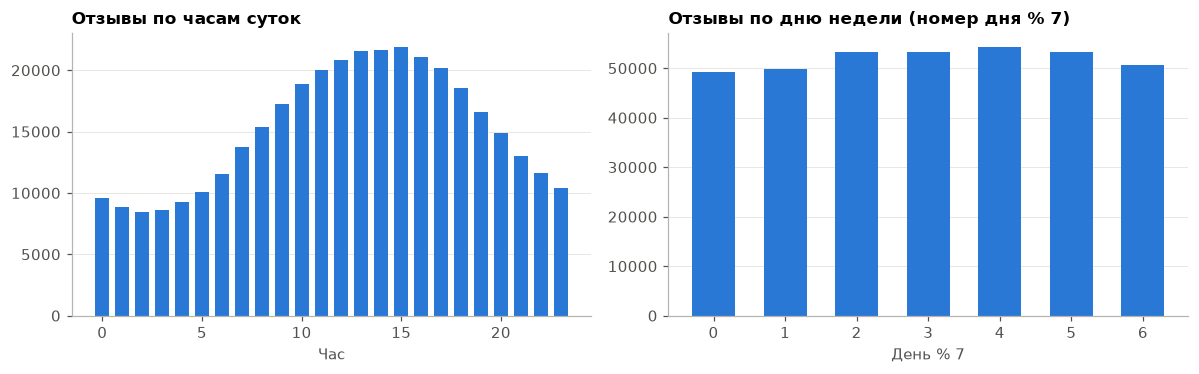

In [19]:
by_hour = reviews_flags.group_by((pl.col("timestamp").dt.total_hours() % 24).alias("hour")).len().sort("hour")
by_weekday = reviews_flags.group_by((pl.col("timestamp").dt.total_days() % 7).alias("weekday")).len().sort("weekday")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(by_hour["hour"], by_hour["len"], color=BLUE, width=0.7)
axes[0].set_title("Отзывы по часам суток", loc="left")
axes[0].set_xlabel("Час")
axes[1].bar(by_weekday["weekday"], by_weekday["len"], color=BLUE, width=0.6)
axes[1].set_title("Отзывы по дню недели (номер дня % 7)", loc="left")
axes[1].set_xlabel("День % 7")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()


### 4.4. Длина текстов

Слова считаем грубо, по пробелам. Для оценки длины этого достаточно.


q0.1,q0.5,q0.9,q0.99,max
f64,f64,f64,f64,u32
6.0,13.0,29.0,58.0,121


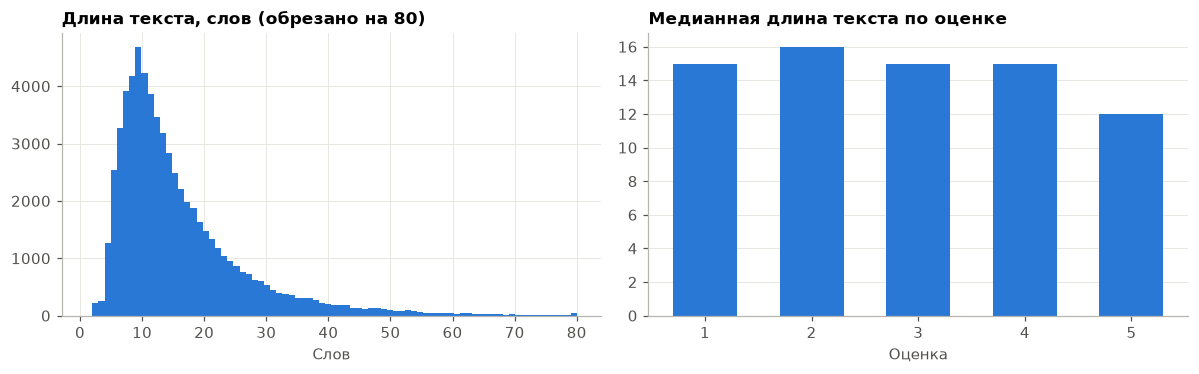

In [20]:
texts = reviews_flags.filter(pl.col("has_text")).with_columns(
    pl.col("text").str.len_chars().alias("n_chars"),
    pl.col("text").str.split(" ").list.len().alias("n_words"),
)
qs = [0.1, 0.5, 0.9, 0.99]
display(texts.select(*[pl.col("n_words").quantile(q).alias(f"q{q}") for q in qs], pl.col("n_words").max().alias("max")))

by_rating = texts.group_by("rating").agg(pl.col("n_words").median().alias("median_words")).sort("rating")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(texts["n_words"].clip(upper_bound=80), bins=80, color=BLUE)
axes[0].set_title("Длина текста, слов (обрезано на 80)", loc="left")
axes[0].set_xlabel("Слов")
axes[1].bar(by_rating["rating"], by_rating["median_words"], color=BLUE, width=0.6)
axes[1].set_title("Медианная длина текста по оценке", loc="left")
axes[1].set_xlabel("Оценка")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()


**Выводы**

**Оценки.** Распределение сильно скошено вправо: 81.9% пятёрок и 10% четвёрок, на 1–3 вместе приходится 8%. Средняя 4.67, медиана 5. Как явный таргет оценка почти бесполезна, потому что почти все ставят 5. Ценнее редкие низкие оценки и сам факт отзыва.

**Динамика.** Средняя оценка по дням стабильна (4.5–4.8). Число отзывов при этом сильно меняется:
- до дня ~1237 в среднем около 2 000 отзывов в день с пиками до 4 250;
- около дня 1238 происходит резкий сдвиг: с 1239 только ~640 отзывов в день, в 3 раза меньше. Авторов за день становится ~250 вместо ~600–1 000, доля отзывов с текстом падает с 19% до 11%, а средняя оценка не меняется;
- из авторов после сдвига только 28% писали отзывы до него.

**Гипотеза:** это изменение в продукте (например, по-другому стали собирать отзывы) или в том, как формировалась выборка Small, а не реальное падение интереса. **Важно для сплита:** если тест взять из последних недель, он будет из "другого режима". Это нужно учесть при выборе train/test.

Последний день (1308) неполный: всего 73 отзыва. Возможно, данные обрезаны посреди дня.

**Время.** Пик отзывов днём, в 13–16 часов, минимум ночью, в 2–3 часа. Возможно, время в UTC, тогда по Москве пик приходится примерно на 16–19. Недельная сезонность слабая: разница между днями ~10%.

**Тексты** короткие: медиана 13 слов, 90% короче 29 слов, максимум 121. К пятёркам пишут чуть короче (медиана 12 слов против 15–16 у остальных оценок). Это согласуется с п. 2.2: недовольные чаще и подробнее объясняют оценку.


## 5. RecSys EDA

### 5.1. Активность пользователей и популярность брендов


In [21]:
user_stats = reviews_flags.group_by("user_id").agg(
    pl.len().alias("n_reviews"),
    pl.col("brand_id").n_unique().alias("n_brands"),
    pl.col("rating").mean().alias("mean_rating"),
    pl.col("timestamp").dt.total_days().n_unique().alias("n_days"),
)
brand_stats = reviews_flags.group_by("brand_id").agg(
    pl.len().alias("n_reviews"),
    pl.col("user_id").n_unique().alias("n_users"),
    pl.col("rating").mean().alias("mean_rating"),
)

qs = [0.5, 0.9, 0.99, 0.999]
for name, df in [("Пользователи", user_stats), ("Бренды", brand_stats)]:
    print(name)
    display(df.select(*[pl.col("n_reviews").quantile(q).alias(f"q{q}") for q in qs], pl.col("n_reviews").max().alias("max")))

display(user_stats.select(
    (pl.col("n_reviews") == 1).mean().alias("users_1_review"),
    (pl.col("n_brands") == 1).mean().alias("users_1_brand"),
    (pl.col("n_brands") >= 5).mean().alias("users_5plus_brands"),
    (pl.col("n_days") == 1).mean().alias("users_1_day"),
))
display(brand_stats.select(
    (pl.col("n_reviews") == 1).mean().alias("brands_1_review"),
    (pl.col("n_reviews") >= 10).mean().alias("brands_10plus_reviews"),
))
display(brand_stats.sort("n_reviews", descending=True).head(5)
        .with_columns((pl.col("n_reviews") / n).round(3).alias("share_of_reviews")))


Пользователи


q0.5,q0.9,q0.99,q0.999,max
f64,f64,f64,f64,u32
1.0,8.0,26.0,55.0,179


Бренды


q0.5,q0.9,q0.99,q0.999,max
f64,f64,f64,f64,u32
1.0,10.0,176.0,2055.0,21530


users_1_review,users_1_brand,users_5plus_brands,users_1_day
f64,f64,f64,f64
0.55112,0.575351,0.189061,0.769353


brands_1_review,brands_10plus_reviews
f64,f64
0.565578,0.100176


brand_id,n_reviews,n_users,mean_rating,share_of_reviews
u64,u32,u32,f64,f64
146468,21530,17427,4.717789,0.059
37799,16675,13728,4.674663,0.046
163178,12078,10379,4.758983,0.033
23403,7381,6468,4.761008,0.02
240838,6932,4412,4.721004,0.019


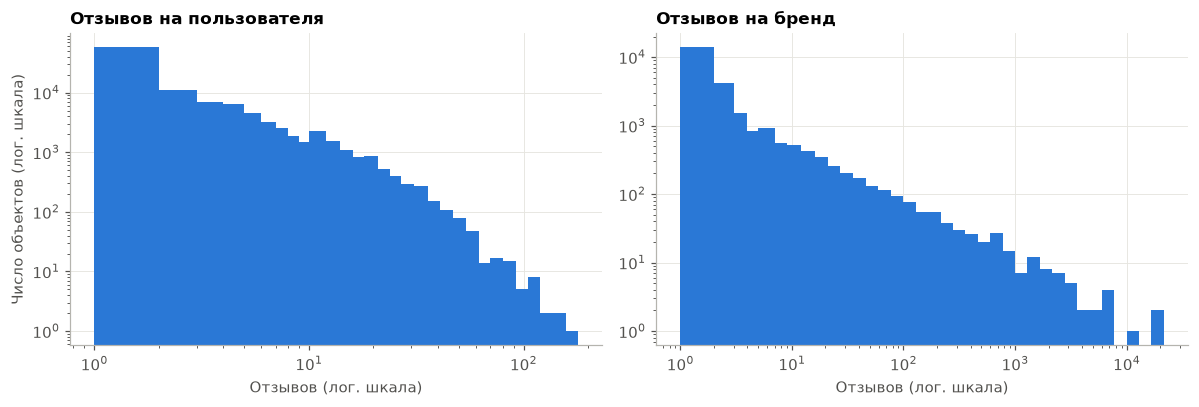

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (df, title) in zip(axes, [(user_stats, "Отзывов на пользователя"), (brand_stats, "Отзывов на бренд")]):
    x = df["n_reviews"].to_numpy()
    bins = np.unique(np.logspace(0, np.log10(x.max() + 1), 40).astype(int))
    ax.hist(x, bins=bins, color=BLUE)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Отзывов (лог. шкала)")
axes[0].set_ylabel("Число объектов (лог. шкала)")
fig.tight_layout()
plt.show()


### 5.2. Длинный хвост: кривые Лоренца и коэффициент Джини

По оси X доля объектов от наименее активных, по Y доля отзывов, которая на них приходится. Коэффициент Джини: 0 — все одинаково активны, 1 — все отзывы у одного объекта. Код такой же, как в EDA offers, поэтому значения можно сравнивать.


Топ-1% пользователей: 11.1% отзывов, топ-10%: 45.6%
Топ-1% брендов: 67.8% отзывов, топ-10%: 88.7%


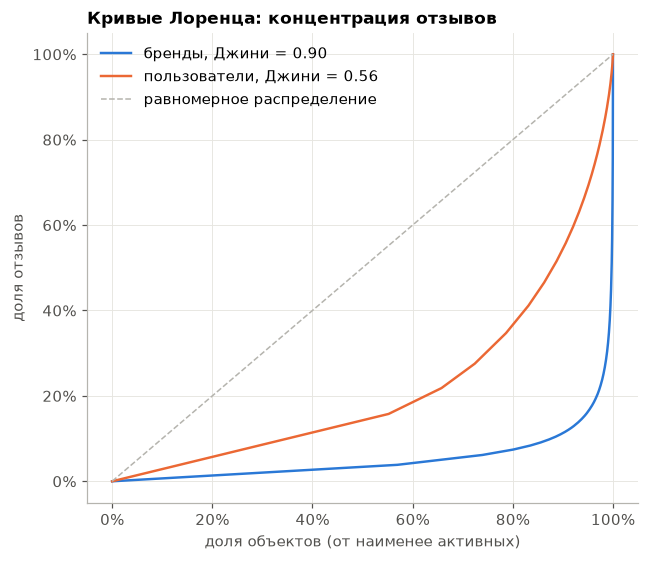

In [23]:
def lorenz(counts):
    x = np.sort(counts.to_numpy())
    cum = np.concatenate([[0], np.cumsum(x) / x.sum()])
    share_obj = np.linspace(0, 1, len(cum))
    gini = 1 - 2 * np.trapezoid(cum, share_obj)
    return share_obj, cum, gini

def top_share(counts, top):
    x = np.sort(counts.to_numpy())[::-1]
    k = int(np.ceil(len(x) * top))
    return x[:k].sum() / x.sum()

for name, df in [("пользователей", user_stats), ("брендов", brand_stats)]:
    print(f"Топ-1% {name}: {top_share(df['n_reviews'], 0.01):.1%} отзывов, топ-10%: {top_share(df['n_reviews'], 0.1):.1%}")

fig, ax = plt.subplots(figsize=(6, 5.2))
for counts, name, color in [(brand_stats["n_reviews"], "бренды", BLUE),
                            (user_stats["n_reviews"], "пользователи", ORANGE)]:
    xs, ys, g = lorenz(counts)
    ax.plot(xs, ys, color=color, label=f"{name}, Джини = {g:.2f}")
ax.plot([0, 1], [0, 1], color="#b5b4ae", linestyle="--", linewidth=1, label="равномерное распределение")
ax.set_xlabel("доля объектов (от наименее активных)")
ax.set_ylabel("доля отзывов")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Кривые Лоренца: концентрация отзывов", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()


### 5.3. Разреженность матрицы user × brand


In [24]:
n_pairs = reviews_flags.select("user_id", "brand_id").unique().height
n_u, n_b = user_stats.height, brand_stats.height
print(f"Непустых пар: {n_pairs:,} из {n_u * n_b:,} возможных, заполненность {n_pairs / (n_u * n_b):.5%}")
print(f"В среднем брендов на пользователя: {n_pairs / n_u:.2f}, пользователей на бренд: {n_pairs / n_b:.2f}")


Непустых пар: 313,176 из 2,540,506,478 возможных, заполненность 0.01233%
В среднем брендов на пользователя: 3.02, пользователей на бренд: 12.80


### 5.4. Оценки брендов и пользователей

Средняя оценка бренда — кандидат в признаки. Считаем её только для брендов от 20 отзывов, иначе среднее слишком шумное.


Брендов от 20 отзывов: 1,410 (5.8%), на них приходится 84.8% отзывов


min,q0.01,q0.1,q0.5,q0.9
f64,f64,f64,f64,f64
1.833333,2.464286,4.321429,4.69697,4.880952


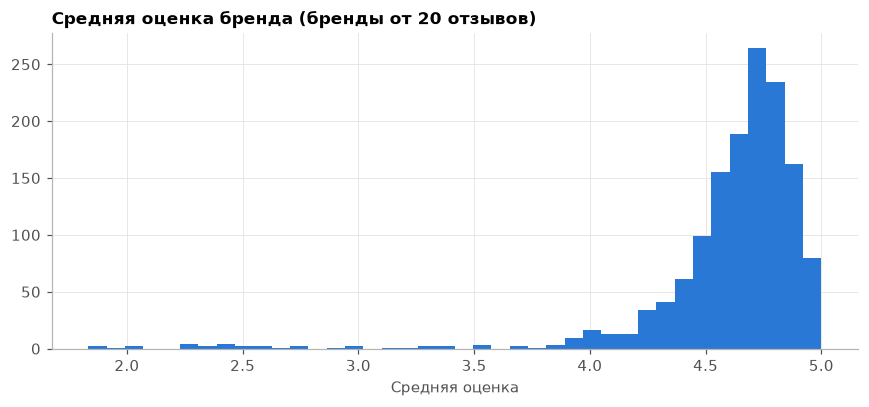

users_5plus_reviews,share_only_fives,share_mean_le_3
u32,f64,f64
22299,0.513072,0.014754


In [25]:
reliable = brand_stats.filter(pl.col("n_reviews") >= 20)
print(f"Брендов от 20 отзывов: {reliable.height:,} ({reliable.height / n_b:.1%}), "
      f"на них приходится {reliable['n_reviews'].sum() / n:.1%} отзывов")
display(reliable.select(
    pl.col("mean_rating").min().alias("min"),
    *[pl.col("mean_rating").quantile(q).alias(f"q{q}") for q in [0.01, 0.1, 0.5, 0.9]],
))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(reliable["mean_rating"], bins=40, color=BLUE)
ax.set_title("Средняя оценка бренда (бренды от 20 отзывов)", loc="left")
ax.set_xlabel("Средняя оценка")
fig.tight_layout()
plt.show()

active_users = user_stats.filter(pl.col("n_reviews") >= 5)
display(active_users.select(
    pl.len().alias("users_5plus_reviews"),
    (pl.col("mean_rating") == 5).mean().alias("share_only_fives"),
    (pl.col("mean_rating") <= 3).mean().alias("share_mean_le_3"),
))


### 5.5. Холодный старт и выбор сплита

Для теста длиной 7, 14 и 28 последних дней смотрим, какая доля тестовых отзывов приходится на пользователей и бренды, которых не было в train, и какая доля — на пары user × brand, уже встречавшиеся в train. Все три окна целиком лежат после сдвига на дне 1239 (п. 4.2).


In [26]:
reviews_day = reviews_flags.with_columns(pl.col("timestamp").dt.total_days().alias("day"))
day_max = reviews_day["day"].max()

rows = []
for test_days in [7, 14, 28]:
    T = day_max - test_days + 1  # первый день теста
    train = reviews_day.filter(pl.col("day") < T)
    test = reviews_day.filter(pl.col("day") >= T)
    rows.append({
        "test_days": test_days,
        "test_reviews": test.height,
        "cold_user": test.join(train.select("user_id").unique(), on="user_id", how="anti").height / test.height,
        "cold_brand": test.join(train.select("brand_id").unique(), on="brand_id", how="anti").height / test.height,
        "repeat_pair": test.join(train.select("user_id", "brand_id").unique(), on=["user_id", "brand_id"], how="semi").height / test.height,
    })
display(pl.DataFrame(rows))


test_days,test_reviews,cold_user,cold_brand,repeat_pair
i64,i64,f64,f64,f64
7,4112,0.521644,0.050827,0.121595
14,8116,0.553351,0.051626,0.113849
28,17289,0.561166,0.053502,0.119787


**Выводы**

**Активность.** Больше половины авторов (55%) оставили ровно один отзыв, 58% писали только об одном бренде, 77% были активны в один день. Медиана — 1 отзыв на пользователя, 99-й перцентиль — 26, максимум — 179. Хотя бы 5 брендов оценили только 19% авторов. Для коллаборативной фильтрации на отзывах это мало: у большинства пользователей одно взаимодействие.

**Концентрация.** Джини 0.90 у брендов и 0.56 у пользователей, почти как в offers (0.91 и 0.71). Топ-1% брендов собирают 68% отзывов, топ-10% — 89%. Самый популярный бренд даёт 6% всех отзывов, второй (`37799`, это бренд с дублями строк в `brands.pq`) — 4.6%. При этом у 57% брендов ровно один отзыв. Средняя оценка бренда надёжна только для небольшой головы.

**Разреженность.** Заполнено 0.012% матрицы user × brand: в среднем 3 бренда на пользователя и 13 пользователей на бренд.

**Оценки брендов.** Брендов от 20 отзывов всего 1 410 (6%), но на них приходится 85% отзывов. Их средняя оценка в основном 4.3–4.9 (10–90-й перцентиль, медиана 4.70), но есть хвост плохих брендов со средней ниже 3. Этот хвост — полезный сигнал "не рекомендовать". У активных пользователей (от 5 отзывов) половина ставит только пятёрки, и лишь 1.5% в среднем ставят <= 3. Оценка сильнее говорит о бренде, чем о вкусе пользователя.

**Холодный старт.** При любом окне теста (7–28 дней) больше половины тестовых отзывов (52–56%) оставляют пользователи, которых не было в train. Новые бренды дают только 5%. Повторных пар user x brand — 12%. Рекомендации по отзывам для "своих" пользователей работают плохо, поэтому reviews лучше использовать **как признаки бренда** (средняя оценка, число отзывов, доля низких оценок, эмбеддинг текстов) для основной модели на других доменах, а не как отдельный источник взаимодействий.


## 6. Связь с другими доменами

Пересечение пользователей reviews с offers и marketplace уже посчитано в EDA этих доменов: 92% авторов отзывов есть в offers и 75% в marketplace. Посмотрим со стороны отзывов: к каким каталогам относятся бренды из отзывов и что отзывы могут дать этим доменам. Связь возможна только через `brand_id` и `user_id`, товаров в отзывах нет.

### 6.1. Бренды из отзывов в каталогах других доменов

Из каталогов читаем только колонку `brand_id`:


In [27]:
brand_stats = brand_stats.join(
    reviews_flags.group_by("brand_id").agg(pl.col("has_text").sum().alias("n_text")), on="brand_id"
)
catalog_brands = {
    d: pl.scan_parquet(PATH / d / "items.pq").select(pl.col("brand_id").drop_nulls().unique()).collect()
    for d in ["retail", "marketplace", "offers"]
}
catalog_brands["хотя бы один"] = pl.concat(catalog_brands.values()).unique()

rows = []
for d, b in catalog_brands.items():
    m = brand_stats.join(b, on="brand_id", how="semi")
    rows.append({
        "domain": d,
        "brands_in_catalog": b.height,
        "with_reviews": m.height,
        "share_catalog_brands": m.height / b.height,
        "share_review_brands": m.height / brand_stats.height,
        "share_reviews": m["n_reviews"].sum() / n,
    })
display(pl.DataFrame(rows))


domain,brands_in_catalog,with_reviews,share_catalog_brands,share_review_brands,share_reviews
str,i64,i64,f64,f64,f64
"""retail""",8,7,0.875,0.000286,0.156983
"""marketplace""",231,97,0.419913,0.003965,0.067201
"""offers""",5683,814,0.143234,0.033269,0.587548
"""хотя бы один""",5843,857,0.146671,0.035027,0.597744


Чем отличаются отзывы на бренды из каталогов и на все остальные:


In [28]:
any_catalog = catalog_brands["хотя бы один"]
display(
    brand_stats.with_columns(pl.col("brand_id").is_in(any_catalog["brand_id"].implode()).alias("in_catalog"))
    .group_by("in_catalog")
    .agg(
        pl.len().alias("n_brands"),
        pl.col("n_reviews").sum().alias("n_reviews"),
        pl.col("n_reviews").median().alias("median_reviews_per_brand"),
        ((pl.col("mean_rating") * pl.col("n_reviews")).sum() / pl.col("n_reviews").sum()).round(3).alias("mean_rating"),
        (pl.col("n_text").sum() / pl.col("n_reviews").sum()).round(3).alias("share_text"),
    )
    .sort("in_catalog")
)


in_catalog,n_brands,n_reviews,median_reviews_per_brand,mean_rating,share_text
bool,u32,u32,f64,f64,f64
false,23610,146409,1.0,4.628,0.18
true,857,217561,8.0,4.698,0.173


### 6.2. Отзывы как замена эмбеддинга бренда

В `brands.pq` эмбеддинг есть у малой доли брендов (п. 2.3, EDA offers п. 1.5). Если у бренда есть отзывы с текстом, из эмбеддингов этих текстов можно собрать его описание (например, усреднить их). Считаем, насколько это расширяет покрытие брендов каждого каталога.


In [29]:
coverage = (
    any_catalog.join(brand_has_emb, on="brand_id", how="left")
    .join(brand_stats.select("brand_id", "n_reviews", "n_text"), on="brand_id", how="left")
    .with_columns(pl.col("has_brand_emb").fill_null(False), pl.col("n_reviews", "n_text").fill_null(0))
)

rows = []
for d in ["retail", "marketplace", "offers"]:
    c = coverage.join(catalog_brands[d], on="brand_id", how="semi")
    rows.append(c.select(
        pl.lit(d).alias("domain"),
        pl.len().alias("n_brands"),
        pl.col("has_brand_emb").mean().alias("brand_emb"),
        (pl.col("n_reviews") > 0).mean().alias("has_reviews"),
        (pl.col("n_text") > 0).mean().alias("has_review_text"),
        (pl.col("has_brand_emb") | (pl.col("n_text") > 0)).mean().alias("brand_emb_or_text"),
    ))
display(pl.concat(rows))


domain,n_brands,brand_emb,has_reviews,has_review_text,brand_emb_or_text
str,u32,f64,f64,f64,f64
"""retail""",8,0.75,0.875,0.875,0.875
"""marketplace""",231,0.17316,0.419913,0.294372,0.324675
"""offers""",5683,0.134964,0.143234,0.101531,0.196199


**Выводы**

- 96.5% брендов из отзывов (23 610 из 24 467) не встречаются ни в одном каталоге. Видимо, это заведения и сервисы, у которых нет товаров и офферов в датасете. На них приходится 40% отзывов, и почти у всех один отзыв (медиана 1)
- Остальные 857 брендов собирают 60% отзывов: 59% приходится на бренды offers, 16% на сети retail, 7% на бренды marketplace (бренды пересекаются между доменами, поэтому суммы больше 60%)
- Средняя оценка и доля текста у этих двух групп почти одинаковые (4.70 против 4.63, 17% против 18%)
- Отзывы есть у 7 из 8 сетей retail, у 42% брендов marketplace и у 14% брендов offers
- **Отзывы расширяют описание брендов.** Эмбеддинг в `brands.pq` есть у 13.5% брендов offers и 17% брендов marketplace. Если добавить усреднённый эмбеддинг текстов отзывов, покрытие вырастает до 20% и 32%. Прирост небольшой. Если он приходится на крупные бренды, польза будет больше: это стоит проверить на событиях offers и marketplace
- Эмбеддинг отзыва (312) и эмбеддинг бренда (300) — разные пространства. Их нельзя смешивать в одном признаке, это должны быть два отдельных признака


## 7. Итоговые выводы

**Данные.** Домен reviews: 363 970 отзывов за 227 дней (дни 1082–1308), 103 834 автора (3% пользователей), 24 467 брендов (83% справочника). В отзыве есть время, пользователь, бренд, оценка 1–5, иногда текст и эмбеддинг текста размерности 312. Товаров нет: отзыв оставляют на бренд.

**Качество данных**

| Таблица | Проблема | Масштаб | Гипотеза | Что делаем |
|---|---|---|---|---|
| reviews | нет текста | 82% отзывов | отзыв — это только оценка; текст чаще пишут к низким оценкам (30% против 16% у пятёрок) | оставляем, `has_text` используем как признак |
| reviews | эмбеддинг без текста | 981 отзыв, 666 уникальных векторов | текст удалили после подсчёта эмбеддинга | эмбеддинг используем как есть |
| reviews | шаблонные тексты | "Neutral review." 155 раз, короткие фразы десятки раз | автогенерация или шаблоны | оставляем, их мало |
| reviews | повторные отзывы на пару user × brand | 12% пар, 25% отзывов | отзыв на каждый визит, не двойная запись (повторов < 1 с всего 2) | не удаляем, агрегируем по паре |
| reviews | резкий сдвиг около дня 1239 | отзывов в день в 3 раза меньше, текстов 11% вместо 19% | изменение в продукте или в выборке Small | учитываем при сплите |
| reviews | последний день неполный | 73 отзыва в день 1308 | данные обрезаны | учитываем при сплите |
| brands | эмбеддинг бренда отсутствует | у 73% брендов из отзывов | см. EDA offers п. 1.5 | частично заменяем эмбеддингом текстов отзывов |

Полных дублей нет. Все пользователи и бренды из отзывов есть в справочниках.

**Главные свойства**
1. Оценки почти все высокие: 82% пятёрок, средняя 4.67. Ценность оценки как сигнала — в редких низких оценках
2. Сильная концентрация по брендам: Джини 0.90, топ-1% брендов дают 68% отзывов, у 57% брендов один отзыв
3. Очень мало взаимодействий на пользователя: у 55% авторов один отзыв, заполнено 0.012% матрицы user × brand
4. Холодный старт по пользователям: при любом окне теста больше половины тестовых отзывов пишут новые пользователи

**Как использовать reviews в рекомендательной системе.** Как самостоятельный источник взаимодействий для коллаборативной фильтрации отзывы слабые. Полезнее строить из них **признаки бренда** для моделей на offers и marketplace: число отзывов (в EDA offers оно умеренно связано с CTR, $\rho$ = 0.46), средняя оценка и доля низких оценок для брендов от ~20 отзывов, усреднённый эмбеддинг текстов. Для пользователя можно взять факт и число отзывов на бренд как сигнал "пользователь был у бренда".
